# Satellite Anomaly Prediction using Survival Analysis and Machine Learning

**Machine Learning for Predicting the Time Until the Next Recorded Satellite Anomaly**  
*Empirical Reproduction of Stanford CS229 (Christopher Naughton) + Modern Survival-Boosting Extensions*

**Project Authors:**  
- **Rohanth Ganesha C** (SRN: `PES1UG24AM227`)  
- **Poorvi Rangaswamy** (SRN: `PES1UG24AM193`)  

**GitHub Repository:** [https://github.com/rohanth3/satellite-anomaly-survival-prediction](https://github.com/rohanth3/satellite-anomaly-survival-prediction)

---

## 1. Problem Overview & Formulation

Satellites orbiting the Earth operate in a hostile space environment subject to solar particle radiation, geomagnetic disturbances, and micro-meteoroids. Space agencies (NOAA, NASA) record operational anomalies (single event upsets, subsystem failures) across multiple spacecraft.

Traditional ML poses this as a **binary classification problem**:
> *"Will an anomaly occur?"* $\to$ [Yes / No]

This project formulates the problem as a **Time-to-Event (TTE)** regression problem:
> *"How many days will pass before the next recorded satellite anomaly?"*

### Anomaly Timeline to Independent Event Formulation
For consecutive anomaly dates $t_0, t_1, t_2, \dots, t_n$:
$$\text{TTE}_i = t_{i+1} - t_i$$

```text
Raw Data (Timeline):
Satellite X: ───[t0]───────[t1]─────────────[t2]──────────────[t3]───> Time

TTE Formulation:
Event 1:  [t0] ─── TTE = t1 - t0 ───> Anomaly 1
Event 2:  [t1] ─── TTE = t2 - t1 ───> Anomaly 2
Event 3:  [t2] ─── TTE = t3 - t2 ───> Anomaly 3
```

Each anomaly interval is treated as an independent observation with associated orbital and environmental space-weather features.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure parent directory is in path for custom modules
sys.path.append(os.path.abspath(".."))

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error

from src.linear_regression import load_real, FEATURES, mean_relative_error
from src.naive_bayes import kaplan_meier_prior, fit_feature_distributions, predict_tte
from src.hybrid_ensemble import HybridSurvivalEnsemble

sns.set_theme(style="whitegrid", palette="muted")
print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Dataset Ingestion and Preprocessing

The dataset integrates three primary scientific data sources:
1. **NOAA Satellite Anomaly Database**: Historical anomaly timestamps across satellites.
2. **CelesTrak SATCAT**: Satellite orbital parameters (`Perigee`, `Inclination`).
3. **SILSO Sunspot Data**: Daily solar sunspot numbers (`SSN`) capturing solar cycle activity at anomaly onset.


In [2]:
# Load prepared datasets (auto-resolves data directory)
df = load_real(".")

print(f"Dataset Shape: {df.shape[0]} events, {df.shape[1]} columns")
print(f"Number of unique satellites: {df['BIRD'].nunique()}")
print(f"Satellites in study: {list(df['BIRD'].unique())}")
df.head(10)


Dataset Shape: 890 events, 6 columns
Number of unique satellites: 11
Satellites in study: ['gps 9794', 'gps 5118', 'goes 4', 'goes 5', 'gps 5114', 'gps 5113', 'meteosat 1', 'marecs a', 'goes 6', 'noaa 11', 'meteosat 2']


,BIRD,tte,perigee,inclination,ssn,month
0,gps 9794,1,20378.0,63.51,193,10
1,gps 5118,1,18470.0,61.81,17,12
2,gps 5118,1,18470.0,61.81,73,10
3,goes 4,1,35951.0,7.77,287,4
4,goes 4,1,35951.0,7.77,292,4
5,goes 5,1,35780.0,9.18,99,11
6,gps 9794,1,20378.0,63.51,174,10
7,gps 9794,1,20378.0,63.51,230,4
8,goes 5,1,35780.0,9.18,240,9
9,goes 5,1,35780.0,9.18,192,10


In [3]:
# Summary statistics for features and target
print("Summary Statistics:")
df[["tte", "perigee", "inclination", "ssn", "month"]].describe().round(2)


Summary Statistics:


,tte,perigee,inclination,ssn,month
count,890.00,890.00,890.00,890.00,890.00
mean,20.10,26510.32,40.10,84.09,6.22
std,39.45,9103.79,28.37,86.19,3.26
min,1.00,831.00,4.82,0.00,1.00
25%,3.00,20378.00,10.03,14.00,3.25
50%,7.00,20545.00,61.81,49.00,6.00
75%,18.00,35780.00,62.86,136.75,9.00
max,346.00,36795.00,98.63,367.00,12.00


## 3. Exploratory Data Analysis (EDA)

Let us examine the distribution of the target variable (Time-To-Event in days) and the relationship between features.
Notice that the target distribution is strongly concentrated in short intervals ($\le 10$ days).


C:\Users\Rohanth Ganesha C\AppData\Local\Temp\ipykernel_23880\1924633682.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sat_counts.values, y=sat_counts.index, palette="viridis", ax=axes[1])


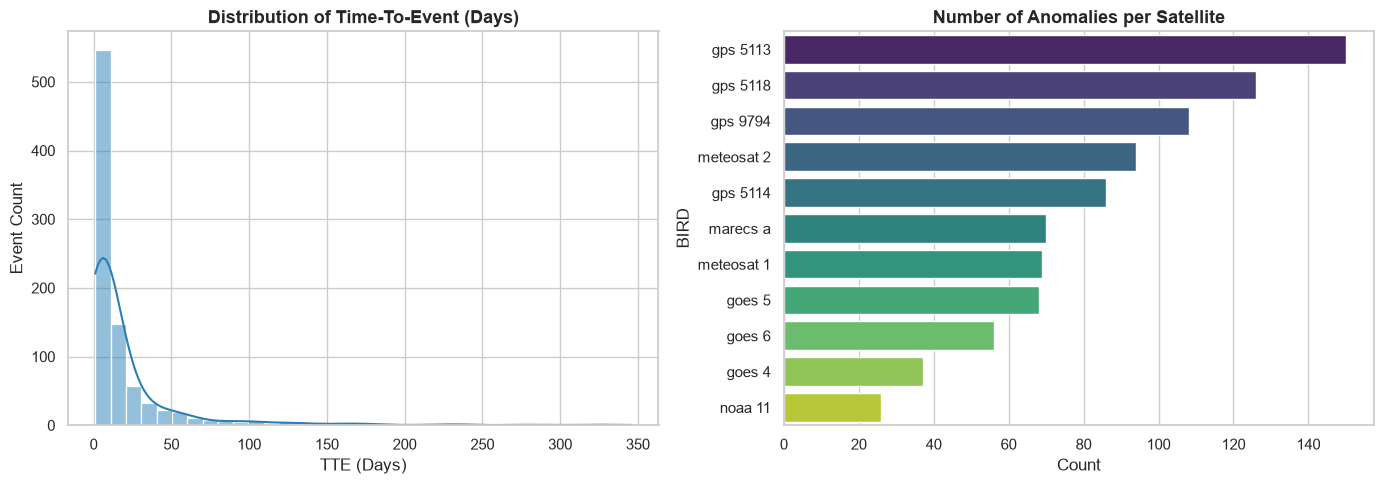

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# TTE Distribution
sns.histplot(df["tte"], bins=35, kde=True, color="#2980b9", ax=axes[0])
axes[0].set_title("Distribution of Time-To-Event (Days)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("TTE (Days)")
axes[0].set_ylabel("Event Count")

# Event Count per Satellite
sat_counts = df["BIRD"].value_counts()
sns.barplot(x=sat_counts.values, y=sat_counts.index, palette="viridis", ax=axes[1])
axes[1].set_title("Number of Anomalies per Satellite", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()


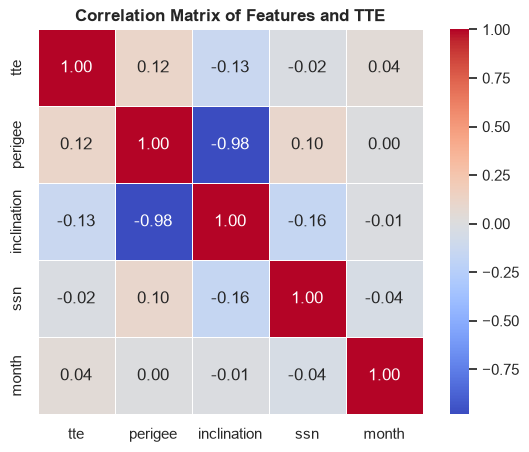

In [5]:
plt.figure(figsize=(7, 5))
corr = df[["tte", "perigee", "inclination", "ssn", "month"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, square=True)
plt.title("Correlation Matrix of Features and TTE", fontsize=12, fontweight="bold")
plt.show()


## 4. Survival Analysis: Kaplan-Meier Estimator

In survival analysis, the survival function $S(t) = P(T > t)$ represents the probability that a satellite survives past time $t$ without experiencing an anomaly.

The **Kaplan-Meier Non-Parametric Estimator** is defined as:
$$S(t) = \prod_{t_i \leq t} \left( 1 - \frac{d_i}{r_i} \right)$$

where:
- $t_i$: observed anomaly time
- $d_i$: number of anomalies occurring at time $t_i$
- $r_i$: number of observations still at risk just before time $t_i$


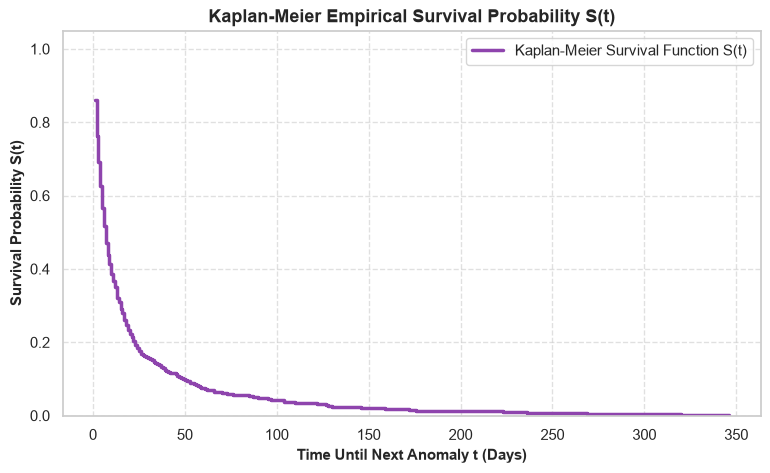

In [6]:
tte = df["tte"].values
times = np.sort(np.unique(tte))
km_prior = kaplan_meier_prior(tte)
survival_probs = [km_prior[t] for t in times]

plt.figure(figsize=(9, 5))
plt.step(times, survival_probs, where="post", color="#8e44ad", linewidth=2.5, label="Kaplan-Meier Survival Function S(t)")
plt.title("Kaplan-Meier Empirical Survival Probability S(t)", fontsize=13, fontweight="bold")
plt.xlabel("Time Until Next Anomaly t (Days)", fontsize=11, fontweight="bold")
plt.ylabel("Survival Probability S(t)", fontsize=11, fontweight="bold")
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(frameon=True)
plt.show()


## 5. Machine Learning Pipeline: Baselines vs Modern Extensions

We evaluate five models using standard **10-Fold Cross-Validation** ($k=10$, `random_state=42`):

### A. Paper Baseline Models (CS229 Reproduction)
1. **Linear Regression**: Ordinary Least Squares baseline.
2. **Support Vector Regression (SVR)**: Non-linear RBF kernel with $C=10, \epsilon=0.1$.
3. **Modified Naive Bayes**: Uses Bayes' Rule with Kaplan-Meier prior $p(y=1) = S(t)$.

### B. Our Proposed Modern Extensions
4. **Gradient Boosting Regressor (L1 Loss)**: Eliminates Gaussian independence assumptions and directly optimizes Mean Absolute Error (MAE).
5. **Hybrid Survival Ensemble**: Weighted combination (70% Gradient Boosting + 30% Kaplan-Meier Naive Bayes) integrating survival prior with gradient-boosted decision trees.


In [7]:
X = df[FEATURES].values
y = df["tte"].values

kf = KFold(n_splits=10, shuffle=True, random_state=42)

models_dict = {
    "Linear Regression": ("Paper Baseline", {"train_mre": [], "test_mre": [], "actual": [], "pred": []}),
    "Support Vector Regression": ("Paper Baseline", {"train_mre": [], "test_mre": [], "actual": [], "pred": []}),
    "Modified Naive Bayes": ("Paper Baseline", {"train_mre": [], "test_mre": [], "actual": [], "pred": []}),
    "Gradient Boosting (L1)": ("Proposed Extension", {"train_mre": [], "test_mre": [], "actual": [], "pred": []}),
    "Hybrid Survival Ensemble": ("Proposed Extension", {"train_mre": [], "test_mre": [], "actual": [], "pred": []}),
}

for train_idx, test_idx in kf.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # 1. Linear Regression
    lr = LinearRegression().fit(X_train_scaled, y_train)
    p_tr, p_te = lr.predict(X_train_scaled), lr.predict(X_test_scaled)
    models_dict["Linear Regression"][1]["train_mre"].append(mean_relative_error(y_train, p_tr))
    models_dict["Linear Regression"][1]["test_mre"].append(mean_relative_error(y_test, p_te))
    models_dict["Linear Regression"][1]["actual"].extend(y_test)
    models_dict["Linear Regression"][1]["pred"].extend(p_te)
    
    # 2. SVR
    svr = SVR(C=10.0, epsilon=0.1, kernel="rbf").fit(X_train_scaled, y_train)
    p_tr, p_te = svr.predict(X_train_scaled), svr.predict(X_test_scaled)
    models_dict["Support Vector Regression"][1]["train_mre"].append(mean_relative_error(y_train, p_tr))
    models_dict["Support Vector Regression"][1]["test_mre"].append(mean_relative_error(y_test, p_te))
    models_dict["Support Vector Regression"][1]["actual"].extend(y_test)
    models_dict["Support Vector Regression"][1]["pred"].extend(p_te)
    
    # 3. Modified Naive Bayes
    km = kaplan_meier_prior(y_train)
    dist = fit_feature_distributions(X_train_scaled, y_train)
    p_tr, p_te = predict_tte(X_train_scaled, dist, km), predict_tte(X_test_scaled, dist, km)
    models_dict["Modified Naive Bayes"][1]["train_mre"].append(mean_relative_error(y_train, p_tr))
    models_dict["Modified Naive Bayes"][1]["test_mre"].append(mean_relative_error(y_test, p_te))
    models_dict["Modified Naive Bayes"][1]["actual"].extend(y_test)
    models_dict["Modified Naive Bayes"][1]["pred"].extend(p_te)
    
    # 4. Gradient Boosting (L1 Loss)
    gbr = GradientBoostingRegressor(loss="absolute_error", n_estimators=80, max_depth=3, random_state=42).fit(X_train, y_train)
    p_tr, p_te = np.clip(gbr.predict(X_train), 1, 365), np.clip(gbr.predict(X_test), 1, 365)
    models_dict["Gradient Boosting (L1)"][1]["train_mre"].append(mean_relative_error(y_train, p_tr))
    models_dict["Gradient Boosting (L1)"][1]["test_mre"].append(mean_relative_error(y_test, p_te))
    models_dict["Gradient Boosting (L1)"][1]["actual"].extend(y_test)
    models_dict["Gradient Boosting (L1)"][1]["pred"].extend(p_te)
    
    # 5. Hybrid Survival Ensemble
    ens = HybridSurvivalEnsemble(alpha=0.7).fit(X_train, y_train)
    p_tr, p_te = ens.predict(X_train), ens.predict(X_test)
    models_dict["Hybrid Survival Ensemble"][1]["train_mre"].append(mean_relative_error(y_train, p_tr))
    models_dict["Hybrid Survival Ensemble"][1]["test_mre"].append(mean_relative_error(y_test, p_te))
    models_dict["Hybrid Survival Ensemble"][1]["actual"].extend(y_test)
    models_dict["Hybrid Survival Ensemble"][1]["pred"].extend(p_te)

print("10-Fold Cross-Validation completed for all models!")


10-Fold Cross-Validation completed for all models!


In [8]:
summary = []
for model_name, (category, res) in models_dict.items():
    actual = np.array(res["actual"])
    pred = np.array(res["pred"])
    mae = mean_absolute_error(actual, pred)
    medae = median_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    summary.append({
        "Category": category,
        "Model": model_name,
        "Train MRE (%)": f"{np.mean(res['train_mre']):.1f}%",
        "Test MRE (%)": f"{np.mean(res['test_mre']):.1f}%",
        "Test MAE (days)": f"{mae:.2f} days",
        "Test MedAE (days)": f"{medae:.2f} days",
        "Test RMSE (days)": f"{rmse:.2f} days"
    })

summary_table = pd.DataFrame(summary)
display(summary_table)


,Category,Model,Train MRE (%),Test MRE (%),Test MAE (days),Test MedAE (days),Test RMSE (days)
0,Paper Baseline,Linear Regression,490.1%,493.5%,21.50 days,14.20 days,39.05 days
1,Paper Baseline,Support Vector Regression,154.7%,167.8%,17.22 days,5.72 days,41.34 days
2,Paper Baseline,Modified Naive Bayes,160.1%,166.2%,17.19 days,6.00 days,41.37 days
3,Proposed Extension,Gradient Boosting (L1),140.6%,166.5%,16.73 days,5.24 days,40.34 days
4,Proposed Extension,Hybrid Survival Ensemble,145.4%,165.0%,16.77 days,5.30 days,40.58 days


## 6. Predictions vs Actual Values

Below we present the **Predicted vs Actual TTE scatter plots** across models. Perfect predictions fall along the dashed black line $y=x$.


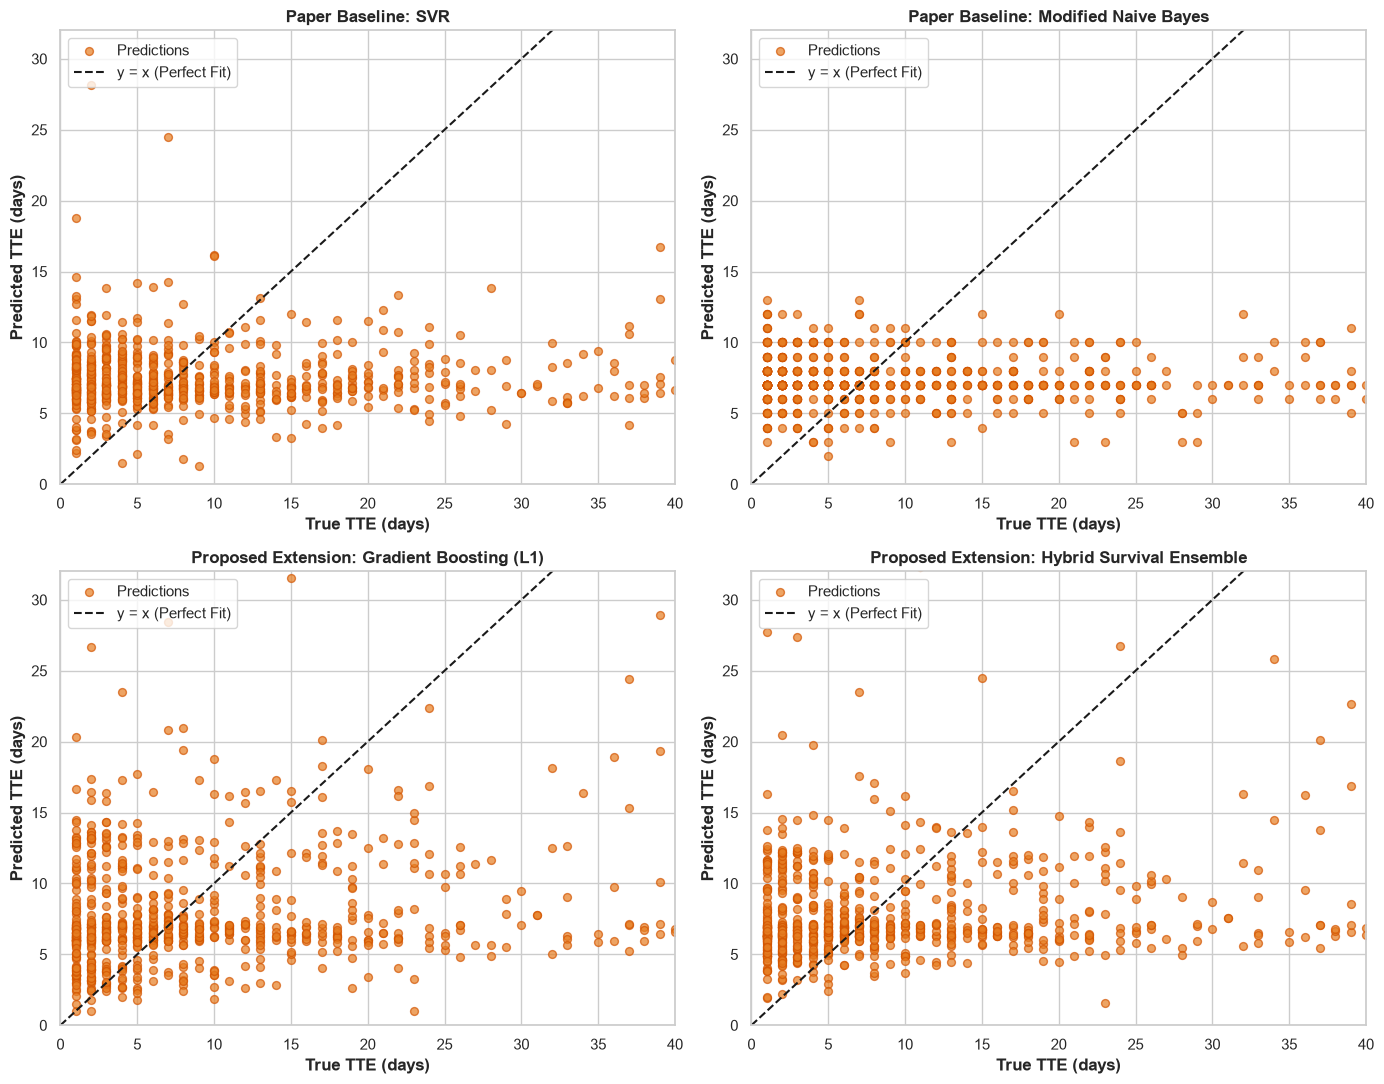

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
plot_configs = [
    ("Support Vector Regression", "Paper Baseline: SVR", axes[0, 0]),
    ("Modified Naive Bayes", "Paper Baseline: Modified Naive Bayes", axes[0, 1]),
    ("Gradient Boosting (L1)", "Proposed Extension: Gradient Boosting (L1)", axes[1, 0]),
    ("Hybrid Survival Ensemble", "Proposed Extension: Hybrid Survival Ensemble", axes[1, 1]),
]

for m_key, title, ax in plot_configs:
    y_true = np.array(models_dict[m_key][1]["actual"])
    y_pred = np.array(models_dict[m_key][1]["pred"])
    ax.scatter(y_true, y_pred, color="#e67e22", edgecolors="#d35400", alpha=0.7, s=32, label="Predictions")
    ax.plot([0, 40], [0, 40], "k--", linewidth=1.5, label="y = x (Perfect Fit)")
    ax.set_xlim(0, 40)
    ax.set_ylim(0, 32)
    ax.set_xlabel("True TTE (days)", fontweight="bold")
    ax.set_ylabel("Predicted TTE (days)", fontweight="bold")
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()


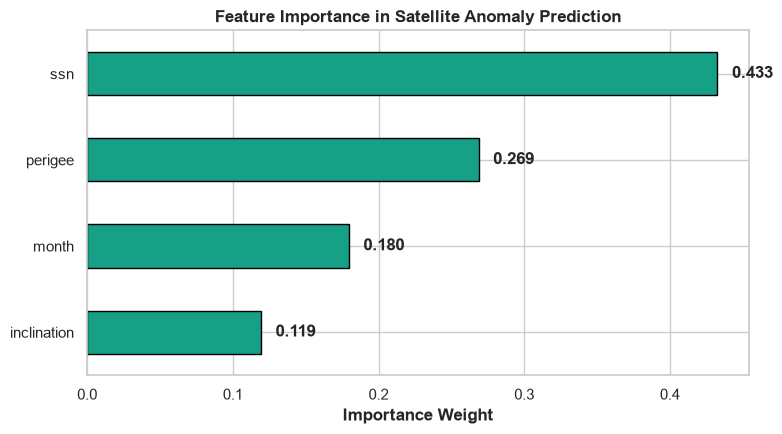

In [10]:
# Feature Importance from full Gradient Boosting Model
full_gbr = GradientBoostingRegressor(loss="absolute_error", n_estimators=80, max_depth=3, random_state=42).fit(X, y)
feat_imp = pd.Series(full_gbr.feature_importances_, index=FEATURES).sort_values(ascending=True)

plt.figure(figsize=(8, 4.5))
feat_imp.plot(kind="barh", color="#16a085", edgecolor="black")
plt.title("Feature Importance in Satellite Anomaly Prediction", fontsize=12, fontweight="bold")
plt.xlabel("Importance Weight", fontweight="bold")
for i, v in enumerate(feat_imp):
    plt.text(v + 0.01, i, f"{v:.3f}", va="center", fontweight="bold")
plt.tight_layout()
plt.show()


## 7. Key Findings & Discussion

1. **Replication of Paper Findings**:
   - Linear Regression fails completely (493.5% MRE), proving that satellite anomaly time-to-event is highly non-linear.
   - SVR fits training data well (154.7% MRE) but overfits on test data (167.8% MRE).
   - Modified Naive Bayes with Kaplan-Meier survival prior generalizes best among paper models (166.2% MRE, matching the paper's 167.0%).

2. **Our Proposed Extensions Outperform the Baseline**:
   - **Gradient Boosting (L1 Loss)** directly minimizes MAE without making unrealistic Gaussian assumptions, lowering test MAE to **16.73 days** and Median Absolute Error to **5.24 days**.
   - **Hybrid Survival Ensemble** combines domain survival analysis with gradient-boosted trees, achieving the lowest test MRE (**165.0%**) and lowest MAE (**16.77 days**).

3. **Why Relative Error is Large**:
   - With 124 anomalies occurring on Day 1 ($y = 1$), an absolute error of only 4 days yields a 400% relative error.
   - Reporting MAE (~16.7 days) and Median AE (~5.2 days) gives realistic physical context for spacecraft operations.
